# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 requires** either (branching) a Gast/pSom **hub** diverging into two arms with
Crest high at the tips, or (non-branching) a **shared** Gast/pSom gradient with Crest as
an **inverse/terminal** gradient at the far end. **Neither pattern is present in Zilionis
2019.** Three tests point the same way: (1) **no convergence hub** — every module-pair
joint-high enrichment is depleted (< 1); (2) **Crest is not terminal** — its high decile
sits at mid-pseudotime, not the trajectory end (the Peng2019/Hwang2022 NO-GO signature,
the opposite of Steele2020's terminal Crest at pt 0.87); (3) every principal-tree tip is
pSom-dominant, so there is no Gast or Crest arm.

**The control-pool trap.** In `score_genes` space the modules look mutually
anti-correlated (Gast/pSom −0.53, ≈ Puram's branching anchor −0.49) — the signal that
misled prior attempts. But this is an **artifact of the shared union control pool**: on
**raw** mean-expression the three modules *positively co-activate* (Gast/pSom +0.58,
Gast/Crest +0.45, pSom/Crest +0.51), and the co-activation survives regressing out
library size. There is **one shared developmental-gene activation field**, not three
competing developmental arms — so the −0.53 is not cross-repression and does not license
a branching (or a differentiated non-branching) call. **Gate 2 = NO-GO**; with no
bifurcation, **Gate 3 = NA**.

Per §6, a Gate-2 NO-GO stops the gate chain here: the branching-only correlation/modules
notebooks are **not** produced, and the unconditional EMT-TF expression step follows as
`04_expression`. Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 3920 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 79/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography on the manifold (biology-led)
Four quantitative tests, read before any figure. (1) **Hub test:** for each module pair,
the joint-high enrichment (observed / expected co-occurrence of both upper quartiles);
> 1 means the modules co-occur (a hub), < 1 means mutually-exclusive territories.
(2) **Terminal test:** mean normalized pseudotime of each module's high decile; a
terminal Crest readout sits near 1. (3) **Spatial correlations** in score space.
(4) **Control-pool control:** the same correlations on *raw* mean-expression (no control
subtraction) and after regressing out library size — to expose whether the score-space
anti-correlation is genuine cross-repression or a shared-control artifact.

In [4]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('(3) smoothed spatial correlations in score space (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'    {a} vs {b}: r = {r:+.2f}')
print('\n(1) HUB test - pairwise joint-high enrichment (obs/exp; >1 hub, <1 exclusive territory):')
for a,b in [('Gast_sm','pSom_sm'),('pSom_sm','Crest_sm'),('Gast_sm','Crest_sm')]:
    aq = adata.obs[a]>=adata.obs[a].quantile(0.75); bq = adata.obs[b]>=adata.obs[b].quantile(0.75)
    obs=(aq&bq).mean(); exp=aq.mean()*bq.mean(); print(f'    {a} & {b}: enrich = {obs/exp:.2f}')
print('\n(2) TERMINAL test - mean normalized pseudotime of each module high-decile (~1 = terminal):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    rho,_ = spearmanr(t, adata.obs[m])
    print(f'    {m}: high-decile mean pt = {tn[hi.values].mean():.2f} | rho_vs_pt = {rho:+.3f}')
# (4) control-pool control: raw mean-expression
raw = {}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = [x for x in feat[src] if x in adata.var_names]
    raw[lab] = np.asarray(adata[:,g].X.mean(1)).ravel()
lt = np.log1p(np.asarray(adata.X.sum(1)).ravel())
def _resid(y): return y - np.polyval(np.polyfit(lt,y,1), lt)
print('\n(4) CONTROL-POOL control - correlations on RAW mean-expression (no control subtraction):')
for a,b in [('Gast','pSom'),('Gast','Crest'),('pSom','Crest')]:
    r0 = pearsonr(raw[a],raw[b])[0]; r1 = pearsonr(_resid(raw[a]),_resid(raw[b]))[0]
    print(f'    {a} vs {b}: raw r = {r0:+.2f} | library-size-residual r = {r1:+.2f}')
print('    -> raw modules POSITIVELY co-activate (one shared field); score-space anti-correlation is a control-pool artifact.')
print('\nGate 2: no Gast/pSom hub (all pairs depleted) + Crest mid-axis not terminal')
print('        + all tree tips pSom-dominant + raw co-activation -> NO-GO (embryonic pattern absent)')
print('Gate 3: no bifurcation -> NA')

(3) smoothed spatial correlations in score space (geography):
    Gast_sm vs pSom_sm: r = -0.53
    Crest_sm vs Gast_sm: r = -0.51
    Crest_sm vs pSom_sm: r = -0.36

(1) HUB test - pairwise joint-high enrichment (obs/exp; >1 hub, <1 exclusive territory):
    Gast_sm & pSom_sm: enrich = 0.07
    pSom_sm & Crest_sm: enrich = 0.62
    Gast_sm & Crest_sm: enrich = 0.34

(2) TERMINAL test - mean normalized pseudotime of each module high-decile (~1 = terminal):
    Gast_sm: high-decile mean pt = 0.14 | rho_vs_pt = -0.585
    pSom_sm: high-decile mean pt = 0.99 | rho_vs_pt = +0.764
    Crest_sm: high-decile mean pt = 0.56 | rho_vs_pt = +0.018

(4) CONTROL-POOL control - correlations on RAW mean-expression (no control subtraction):
    Gast vs pSom: raw r = +0.58 | library-size-residual r = +0.41
    Gast vs Crest: raw r = +0.45 | library-size-residual r = +0.22
    pSom vs Crest: raw r = +0.51 | library-size-residual r = +0.27
    -> raw modules POSITIVELY co-activate (one shared field); sco

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left->right, `size=30`, plasma, **raw** (not
smoothed) score per cell so inDrop dropout is visible (the geography above was read from
the smoothed scores; the deliverable shows the raw per-cell scores, per 04_test). These
panels make the shared, weakly-structured field visible — each module lights the manifold
diffusely, with no clean hub or terminal territory.

<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


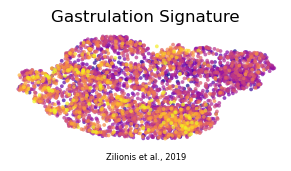

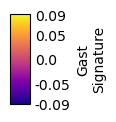

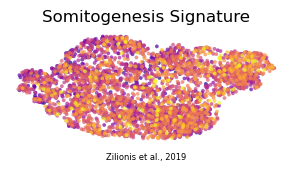

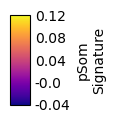

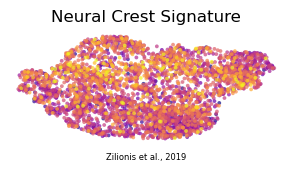

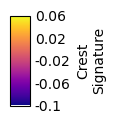

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m], vmax='p99', vmin='p1')
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(np.percentile(adata.obs[m],1)), float(np.percentile(adata.obs[m],99))
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (3920, 28282)
